[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_congestion/BA_L1_congestion.ipynb)

# BA_L1_congestion: When Blocks Fill Up, Fees Rise

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monthly mean Bitcoin block size against the average fee per transaction (log scale), coloured by year, November 2014 to October 2025, with the correlation of the logs and the median fee in the months with the fullest and the emptiest blocks.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Monthly means of three daily on-chain series of Bitcoin: mean block size (bytes, shown in thousands), average fee per
transaction (USD) and transactions per day. Block space is limited; when more users compete for it, they offer higher
fees to be included sooner.

**How to read the chart.** One point per month, coloured by year; the fee axis is logarithmic. Points to the right
(fuller blocks) sit higher on average. The relation is an association of monthly means, not a demand curve.

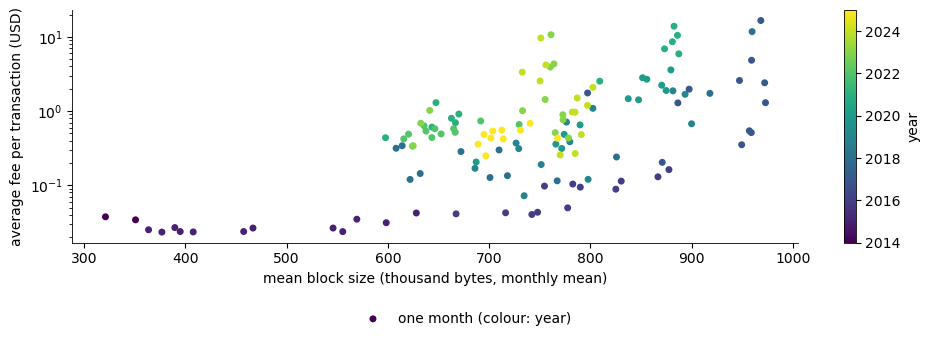

132 months; correlation of log fee with log block size 0.65, with log transactions 0.63
Median fee in the quarter of months with the fullest blocks (>= 813 thousand bytes): 1.88 USD; in the emptiest quarter (<= 664): 0.32 USD
2017-12: block size 968 thousand bytes, fee 16.63 USD
2023-12: block size 761 thousand bytes, fee 10.70 USD
2025-09: block size 697 thousand bytes, fee 0.25 USD


In [5]:
# Bitcoin: monthly mean block size and average fee per transaction
cong = pd.DataFrame({'size': load_onchain('blocksize')['BTC'] / 1e3, 'fee': load_onchain('transactionfee')['BTC'],
                     'tx': load_onchain('transaction')['BTC']}).resample('ME').mean().dropna()
r_size = np.corrcoef(np.log(cong['size']), np.log(cong['fee']))[0, 1]
r_tx = np.corrcoef(np.log(cong['tx']), np.log(cong['fee']))[0, 1]

fig, ax = plt.subplots(figsize=(10, 3.4))
sc = ax.scatter(cong['size'], cong['fee'], c=cong.index.year, cmap='viridis', s=16, label='one month (colour: year)')
ax.set_yscale('log'); ax.set_xlabel('mean block size (thousand bytes, monthly mean)'); ax.set_ylabel('average fee per transaction (USD)')
fig.colorbar(sc, ax=ax).set_label('year')
legend_below(fig, ncol=1, bottom=0.10)
save_fig(fig, 'ba_l1_congestion')

full_q = cong['size'] >= cong['size'].quantile(0.75); empty_q = cong['size'] <= cong['size'].quantile(0.25)
print(f'{len(cong)} months; correlation of log fee with log block size {r_size:.2f}, with log transactions {r_tx:.2f}')
print(f'Median fee in the quarter of months with the fullest blocks (>= {cong["size"].quantile(0.75):.0f} thousand bytes): '
      f'{cong.loc[full_q, "fee"].median():.2f} USD; in the emptiest quarter (<= {cong["size"].quantile(0.25):.0f}): {cong.loc[empty_q, "fee"].median():.2f} USD')
for d in ['2017-12', '2023-12', '2025-09']:
    print(f'{d}: block size {cong.loc[d, "size"].iloc[0]:.0f} thousand bytes, fee {cong.loc[d, "fee"].iloc[0]:.2f} USD')